# Dados e Aprendizagem Automática 26/27
## Trabalho Prático — Previsão do escalão etário (INS 2019)

**Objetivo:** prever `AGE_RANGE` (16 classes, 0 = 15–17 … 15 = 85+) a partir do perfil socioeconómico, de saúde e de estilos de vida; identificar anomalias (idade prevista ≠ idade real) e caracterizar cada escalão.

**Métrica:** Macro F1 (todas as classes pesam o mesmo).

Estrutura:
1. Carregar e compreender os dados
2. Preparação e transformação
3. EDA
4. Modelação e validação (Decision Tree, Logistic Regression, Gradient Boosting)
5. Otimização para Macro F1
6. Interpretação do modelo
7. Anomalias epidemiológicas
8. Caracterização dos escalões
9. Submissão

In [1]:
import re
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, confusion_matrix, classification_report

sns.set_style('whitegrid')
pd.set_option('display.max_columns', 50)
SEED = 2026
K = 16
AGE_LABELS = ['15-17','18-19','20-24','25-29','30-34','35-39','40-44','45-49',
              '50-54','55-59','60-64','65-69','70-74','75-79','80-84','85+']

## 1. Carregar e compreender os dados

In [3]:
train = pd.read_csv('datasets/dataset_train.csv', dtype=str)
test = pd.read_csv('datasets/dataset_test_X.csv', dtype=str)
print('train:', train.shape, '| test:', test.shape)
train.head()

train: (10962, 237) | test: (3655, 236)


,PID,HHID,PROXY,REFYEAR,REFMONTH,COUNTRY,NUTS1,REGION,NUTS2_AG,DEG_URB,SEX,AGE_RANGE,BIRTHPLACE_COD,CITIZEN_COD,BIRTHPLACEFATH_COD,BIRTHPLACEMOTH_COD,MARSTALEGAL,PARTNERS,IN1,IN2,IN3,IN4,HATLEVEL,MAINSTAT,FT_PT,...,AL3,AL4,AL5,AL6,IN50,IN51,IN52,IN53,IN54,SS1,SS2,SS3,IC1,IC2,IC3,IN10,IN11,IN12,IN13,IN14,IN55,IN56,IN57,IN59,IN67
0,1242.0,124201.0,1.0,2019,10,PT,Continente,Norte,Norte,Áreas densamente povoadas,Homem,13,Autóctone (PT),Nacional (PT),Autóctone (PT),Autóctone (PT),Divorciado,Não aplicável,Sim,Não aplicável,Não aplicável,Não aplicável,Básico 1º e 2º ciclo,Tem um emprego ou trabalho (inc. trabalhador f...,Tempo completo,...,2 bebidas por dia,3 dias,3 bebidas por dia,Menos de uma vez por mês,Nem de acordo nem em desacordo,Em desacordo,Nem de acordo nem em desacordo,Mais ou menos de acordo,Totalmente em desacordo,6 ou mais,Muita preocupação e interesse,Muito difícil,Não,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não
1,8881.0,888102.0,1.0,2020,1,PT,Continente,Alentejo,Alentejo,Áreas pouco povoadas,Homem,5,Autóctone (PT),Nacional (PT),Autóctone (PT),Autóctone (PT),Solteiro,Sem relação de conjugalidade,Sim,Não aplicável,Não aplicável,Não aplicável,Secundário,Tem um emprego ou trabalho (inc. trabalhador f...,Tempo completo,...,2 bebidas por dia,3 dias,4 a 5 bebidas por dia,2 a 3 dias por mês,Mais ou menos de acordo,Nem de acordo nem em desacordo,De acordo,Mais ou menos de acordo,Mais ou menos de acordo,1 ou 2,Muita preocupação e interesse,Difícil,Não,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não
2,399.0,39902.0,1.0,2019,12,PT,Continente,Norte,Norte,Áreas densamente povoadas,Mulher,9,Autóctone (PT),Nacional (PT),Autóctone (PT),Autóctone (PT),Casado,Com relação de conjugalidade legal ou de facto,Sim,Não aplicável,Não aplicável,Não aplicável,Básico 1º e 2º ciclo,Tem um emprego ou trabalho (inc. trabalhador f...,Tempo completo,...,Não aplicável,Não aplicável,Não aplicável,"Nunca consumiu, ou só ocasionalmente para provar",Mais ou menos de acordo,De acordo,De acordo,De acordo,De acordo,3 a 5,Alguma preocupação e interesse,Muito fácil,Sim,Familiar do respondente,Menos de 10 horas,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Sem resposta,Não aplicável,Não aplicável,40.0,Não aplicável,Sim
3,10589.0,1058901.0,1.0,2019,11,PT,Continente,Alentejo,Lx V Tejo,Áreas mediamente povoadas,Mulher,13,Autóctone (PT),Nacional (PT),Autóctone (PT),Autóctone (PT),Viúvo,Não aplicável,Sim,Não aplicável,Não aplicável,Não aplicável,Básico 1º e 2º ciclo,"Reformado, com reforma antecipada ou cessou a ...",Não aplicável,...,Não aplicável,Não aplicável,Não aplicável,Não aplicável,De acordo,Mais ou menos em desacordo,De acordo,Mais ou menos de acordo,Mais ou menos de acordo,Nenhuma,Nenhuma preocupação e interesse,Muito fácil,Não,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não
4,6875.0,687501.0,1.0,2019,10,PT,Continente,Centro (PT),Lx V Tejo,Áreas pouco povoadas,Mulher,14,Autóctone (PT),Nacional (PT),Autóctone (PT),Autóctone (PT),Viúvo,Não aplicável,Sim,Não aplicável,Não aplicável,Não aplicável,Nenhum nível completado,"Reformado, com reforma antecipada ou cessou a ...",Não aplicável,...,Não aplicável,Não aplicável,Não aplicável,Não aplicável,De acordo,De acordo,De acordo,De acordo,De acordo,1 ou 2,Não consegue avaliar,Muito fácil,Não,Não aplicável,Não aplicável,Não,Não aplicável,Não aplicável,Não aplicável,"Doença, exceto doença profissional",Não aplicável,Não aplicável,Não aplicável,Não aplicável,Não


In [4]:
# Colunas com um único valor (não trazem informação) e identificadores
const = [c for c in train.columns if train[c].nunique() == 1]
print('Constantes:', const)
print('PID/HHID únicos no treino:', train.PID.nunique(), train.HHID.nunique(),
      '| agregados partilhados treino/teste:', len(set(train.HHID) & set(test.HHID)))

Constantes: ['PROXY', 'COUNTRY']
PID/HHID únicos no treino: 10962 10962 | agregados partilhados treino/teste: 0


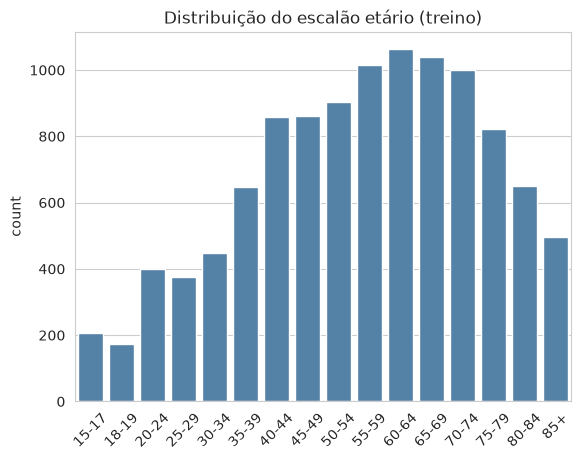

,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
n,207,172,399,377,449,647,859,862,905,1014,1062,1040,1000,823,650,496


In [5]:
y = train['AGE_RANGE'].astype(int).values
ax = sns.countplot(x=y, color='steelblue')
ax.set_xticks(range(K)); ax.set_xticklabels(AGE_LABELS, rotation=45)
ax.set_title('Distribuição do escalão etário (treino)'); ax.set_xlabel(''); plt.show()
pd.Series(y).value_counts().sort_index().rename(index=dict(enumerate(AGE_LABELS))).to_frame('n').T

As classes estão desequilibradas: os escalões 15–17 e 18–19 têm 5× menos indivíduos do que 60–64. Com Macro F1, estas classes pequenas pesam o mesmo que as grandes, o que justifica pesos por classe (`class_weight='balanced'`).

**Codificação dos valores:** quase todas as colunas vêm como texto. Nas colunas numéricas aparecem códigos especiais:

In [6]:
from collections import Counter
tokens = Counter()
for c in train.columns:
    v = train[c].dropna()
    num = pd.to_numeric(v, errors='coerce')
    if num.notna().mean() > 0.5:
        tokens.update(v[num.isna()])
tokens.most_common()

[('Não aplicável', 6301),
 ('Sem resposta', 1802),
 ('>= 25', 93),
 ('>=3', 88),
 ('>=7', 40),
 ('>= 60', 11)]

- `Não aplicável` → a pergunta **não foi feita** (regra de salto do questionário) — é informação, não um valor em falta.
- `Sem resposta` → não respondeu.
- `>= 25`, `>=7`, … → valores truncados no topo.

## 2. Preparação e transformação
Decisões:
- remover identificadores (`PID`, `HHID`) e constantes;
- colunas numéricas: converter, `Não aplicável` → -1, `Sem resposta` → -2 (os modelos de árvores separam estes códigos sem problema);
- colunas de texto: categorias (mantendo `Não aplicável`/`Sem resposta` como categorias próprias).

In [7]:
SPECIAL = {'Não aplicável': -1.0, 'Sem resposta': -2.0}

def to_num(s):
    s = s.replace(SPECIAL)
    s = s.map(lambda x: float(re.sub(r'[^\d.]', '', x)) if isinstance(x, str) and x.strip().startswith('>=') else x)
    return pd.to_numeric(s, errors='coerce')

drop_cols = ['PID', 'HHID', 'AGE_RANGE'] + const
full = pd.concat([train.drop(columns=['AGE_RANGE']), test], ignore_index=True)
full = full.drop(columns=[c for c in drop_cols if c in full.columns])

num_cols, cat_cols = [], []
for c in full.columns:
    conv = to_num(full[c].dropna())
    if conv.notna().mean() > 0.95:
        full[c] = to_num(full[c]); num_cols.append(c)
    else:
        full[c] = full[c].fillna('NA').astype('category'); cat_cols.append(c)
print(len(num_cols), 'numéricas |', len(cat_cols), 'categóricas')

41 numéricas | 191 categóricas


### 2.1 Regras de salto do questionário
Algumas perguntas só são feitas a certas idades. Para cada coluna, vemos em que escalões a resposta é **sempre** (>98%) `Não aplicável`:

In [8]:
na_mask = full.iloc[:len(train)].astype(str).isin(['Não aplicável', '-1.0'])
rows = []
for c in full.columns:
    p = na_mask[c].groupby(y).mean()
    if 0.02 < na_mask[c].mean() < 0.98:
        never = [AGE_LABELS[k] for k in p.index[p > 0.98]]
        if never:
            rows.append((c, round(na_mask[c].mean(), 2), never))
skip = pd.DataFrame(rows, columns=['coluna', '% não aplicável', 'escalões onde nunca é perguntada'])
skip

,coluna,% não aplicável,escalões onde nunca é perguntada
0,IN2,0.87,"[15-17, 18-19]"
1,IN3,0.88,"[15-17, 18-19, 20-24]"
2,IN4,0.93,"[80-84, 85+]"
3,FT_PT,0.56,"[15-17, 75-79, 80-84, 85+]"
4,JOBSTAT_COD,0.56,"[15-17, 75-79, 80-84, 85+]"
5,JOBISCO_COD,0.56,"[15-17, 75-79, 80-84, 85+]"
6,LOCNACE_COD,0.56,"[15-17, 75-79, 80-84, 85+]"
7,AC_IN1,0.96,[35-39]
8,AC_IN2,0.97,"[20-24, 35-39, 40-44, 45-49]"
9,AW1,0.56,"[15-17, 75-79, 80-84, 85+]"


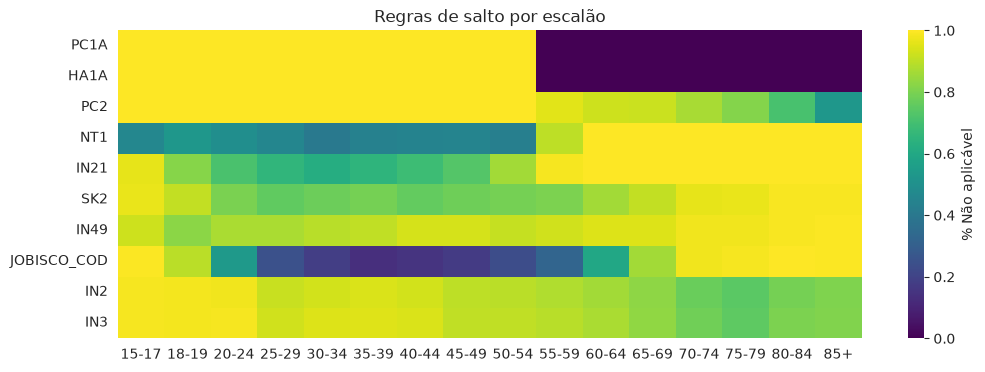

In [9]:
plot_cols = ['PC1A', 'HA1A', 'PC2', 'NT1', 'IN21', 'SK2', 'IN49', 'JOBISCO_COD', 'IN2', 'IN3']
heat = na_mask[plot_cols].groupby(y).mean().T
heat.columns = AGE_LABELS
plt.figure(figsize=(12, 4))
sns.heatmap(heat, cmap='viridis', cbar_kws={'label': '% Não aplicável'})
plt.title('Regras de salto por escalão'); plt.show()

**Achado importante:** os módulos PC1/HA1 (cuidados pessoais e tarefas domésticas) só são perguntados a quem tem **≥ 55 anos**. Por isso `PC1A == 'Não aplicável'` separa **perfeitamente** as classes 0–8 das classes 9–15. Outras regras: o módulo NT não é perguntado a ≥ 60 anos, e SK2/IN49 (tabaco) não é perguntado a ≥ 80. O modelo vai aprender estas fronteiras, e convém discuti-las no relatório: são um artefacto do desenho do inquérito, não uma característica de saúde.

### 2.2 Feature engineering

In [10]:
h = full['BM1'].where(full['BM1'] > 0)
w = full['BM2'].where(full['BM2'] > 0)
full['BMI'] = w / (h / 100) ** 2

cd_cols = [f'CD1{l}' for l in 'ABCDEFGHIJKLMNOP']
full['N_CHRONIC'] = (full[cd_cols].astype(str) == 'Sim').sum(axis=1)

lim_cols = [c for c in full.columns if re.match(r'^(PC1|HA1)[A-G]$', c)]
ok = ['Nenhuma dificuldade', 'Não aplicável', 'NA', 'Sem resposta',
      'Não aplicável (nunca tentou ou não precisa de o fazer)']
full['N_LIMIT'] = (~full[lim_cols].astype(str).isin(ok)).sum(axis=1)

X = full.iloc[:len(train)].reset_index(drop=True)
X_test = full.iloc[len(train):].reset_index(drop=True)
print(X.shape, X_test.shape)
X[['BMI', 'N_CHRONIC', 'N_LIMIT']].describe().T

(10962, 235) (3655, 235)


,count,mean,std,min,25%,50%,75%,max
BMI,10559.0,26.349523,4.524815,14.609204,23.183532,25.806452,29.03179,53.972002
N_CHRONIC,10962.0,2.561485,2.480304,0.000000,0.000000,2.000000,4.00000,13.000000
N_LIMIT,10962.0,0.753330,1.895813,0.000000,0.000000,0.000000,0.00000,12.000000


## 3. EDA — relação das variáveis com a idade

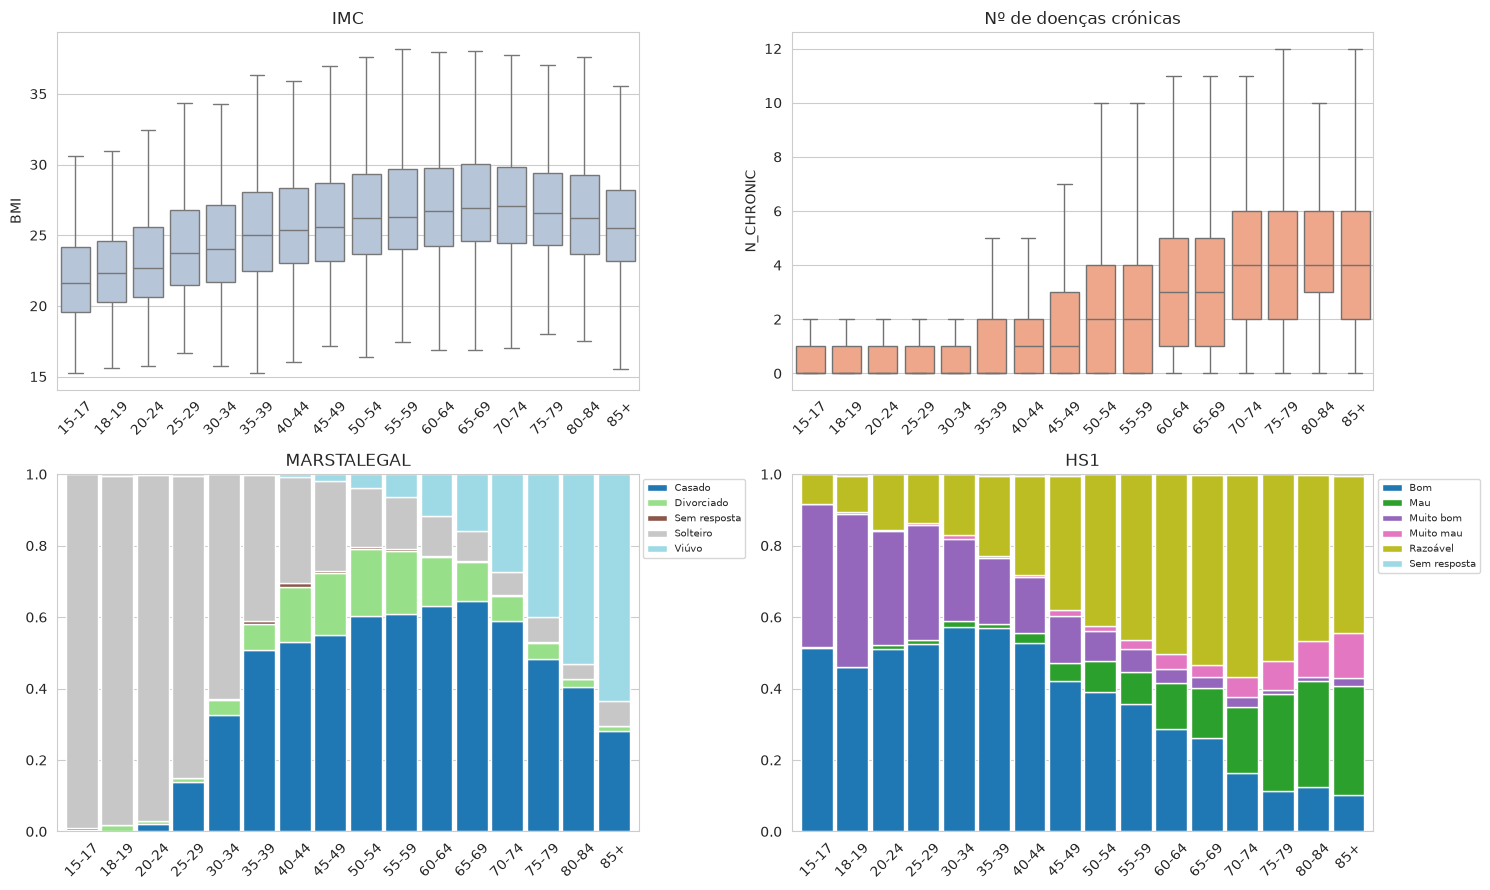

In [11]:
eda = X.copy(); eda['AGE'] = pd.Categorical([AGE_LABELS[k] for k in y], categories=AGE_LABELS, ordered=True)
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
sns.boxplot(x='AGE', y='BMI', data=eda, ax=axs[0, 0], color='lightsteelblue', showfliers=False)
sns.boxplot(x='AGE', y='N_CHRONIC', data=eda, ax=axs[0, 1], color='lightsalmon', showfliers=False)
for col, ax in [('MARSTALEGAL', axs[1, 0]), ('HS1', axs[1, 1])]:
    pd.crosstab(eda['AGE'], eda[col], normalize='index').plot(kind='bar', stacked=True, ax=ax, colormap='tab20', width=0.9)
    ax.legend(fontsize=7, loc='upper left', bbox_to_anchor=(1, 1)); ax.set_title(col)
for ax in axs.flat:
    ax.tick_params(axis='x', rotation=45); ax.set_xlabel('')
axs[0, 0].set_title('IMC'); axs[0, 1].set_title('Nº de doenças crónicas')
plt.tight_layout(); plt.show()

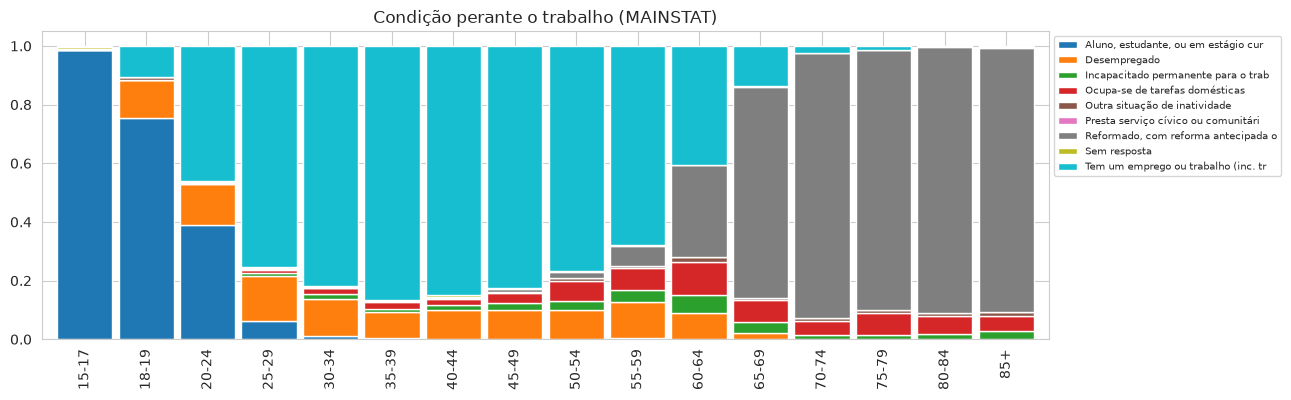

In [12]:
ms = pd.crosstab(eda['AGE'], eda['MAINSTAT'], normalize='index')
ms.columns = [c[:35] for c in ms.columns]
ms.plot(kind='bar', stacked=True, figsize=(13, 4), colormap='tab10', width=0.9)
plt.legend(fontsize=7, bbox_to_anchor=(1, 1)); plt.title('Condição perante o trabalho (MAINSTAT)'); plt.xlabel(''); plt.show()

Padrões claros: os estudantes dominam até aos 19 anos e a reforma sobe dos 60 aos 69; o casamento aumenta até aos 69 e a viuvez cresce depois; o número de doenças crónicas aumenta de forma monótona com a idade.

## 4. Modelação e validação
Protocolo comum a todos os modelos: **StratifiedKFold com 5 folds** e Macro F1 calculada sobre as previsões *out-of-fold* (OOF). Guardamos também as probabilidades OOF, que são usadas na otimização (secção 5) e nas anomalias (secção 7).

In [13]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def run_cv(make_model, Xtr, Xte, name):
    t = time.time()
    oof = np.zeros((len(Xtr), K)); te = np.zeros((len(Xte), K))
    for a, b in skf.split(Xtr, y):
        m = make_model().fit(Xtr.iloc[a], y[a])
        oof[b] = m.predict_proba(Xtr.iloc[b])
        te += m.predict_proba(Xte) / skf.n_splits
    f1s = [f1_score(y[b], oof[b].argmax(1), average='macro') for _, b in skf.split(Xtr, y)]
    print(f'{name}: Macro F1 = {np.mean(f1s):.4f} ± {np.std(f1s):.4f}  ({time.time()-t:.0f}s)')
    return oof, te

results = {}

### 4.1 Decision Tree
As árvores do scikit-learn precisam de entradas numéricas, por isso as categorias passam por `OrdinalEncoder`. Os hiperparâmetros são afinados com `GridSearchCV`, usando `scoring='f1_macro'`.

In [14]:
X_ord = X.copy(); X_test_ord = X_test.copy()
enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_ord[cat_cols] = enc.fit_transform(X[cat_cols].astype(str))
X_test_ord[cat_cols] = enc.transform(X_test[cat_cols].astype(str))
X_ord = X_ord.fillna(-3); X_test_ord = X_test_ord.fillna(-3)

grid_dt = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=SEED),
                       {'max_depth': [6, 8, 10, 14], 'min_samples_leaf': [5, 20, 50]},
                       scoring='f1_macro', cv=skf, n_jobs=-1)
grid_dt.fit(X_ord, y)
print('Melhores parâmetros:', grid_dt.best_params_, '| F1:', round(grid_dt.best_score_, 4))
best_dt = grid_dt.best_params_
results['Decision Tree'] = run_cv(lambda: DecisionTreeClassifier(class_weight='balanced', random_state=SEED, **best_dt),
                                  X_ord, X_test_ord, 'Decision Tree')

Melhores parâmetros: {'max_depth': 10, 'min_samples_leaf': 5} | F1: 0.3987
Decision Tree: Macro F1 = 0.3987 ± 0.0174  (4s)


### 4.2 Logistic Regression
As categorias passam por one-hot encoding e as variáveis numéricas por normalização. Este modelo serve de referência linear.

In [15]:
pre = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10), cat_cols),
    ('num', StandardScaler(), [c for c in X.columns if c not in cat_cols])])
X_lr = X.copy(); X_test_lr = X_test.copy()
for d in (X_lr, X_test_lr):
    d[cat_cols] = d[cat_cols].astype(str)
    d[d.columns.difference(cat_cols)] = d[d.columns.difference(cat_cols)].fillna(-3)

results['Logistic Regression'] = run_cv(
    lambda: make_pipeline(pre, LogisticRegression(C=0.05, class_weight='balanced', max_iter=300)),
    X_lr, X_test_lr, 'Logistic Regression')

Logistic Regression: Macro F1 = 0.4281 ± 0.0102  (143s)


### 4.3 Gradient Boosting (HistGradientBoosting)
Este modelo é uma extensão do que foi dado nas aulas. É um ensemble de árvores construídas sequencialmente, em que cada árvore corrige os erros das anteriores. Lida nativamente com variáveis categóricas e com valores em falta. Em casa, pode ser trocado por LightGBM ou CatBoost, que têm a mesma lógica.

In [15]:
def make_hgb():
    return HistGradientBoostingClassifier(
        learning_rate=0.06, max_iter=600, max_leaf_nodes=31, min_samples_leaf=20,
        l2_regularization=1.0, categorical_features='from_dtype', class_weight='balanced',
        early_stopping=True, validation_fraction=0.1, n_iter_no_change=40, random_state=SEED)

results['HistGradientBoosting'] = run_cv(make_hgb, X, X_test, 'HistGradientBoosting')

HistGradientBoosting: Macro F1 = 0.4552 ± 0.0024  (172s)


In [16]:
comp = pd.DataFrame({name: {'Macro F1 (OOF)': f1_score(y, o.argmax(1), average='macro'),
                            'Erro médio (nº de classes)': np.abs(o.argmax(1) - y).mean()}
                     for name, (o, _) in results.items()}).T.round(4)
comp

,Macro F1 (OOF),Erro médio (nº de classes)
Decision Tree,0.4008,0.9623
Logistic Regression,0.4282,0.8223
HistGradientBoosting,0.4554,0.7496


## 5. Otimização para Macro F1
O `argmax` das probabilidades não maximiza a Macro F1. Uma técnica simples é multiplicar a probabilidade de cada classe por um peso $w_k$ e escolher os pesos que maximizam a Macro F1 nas previsões OOF (*coordinate ascent*). Como os pesos são afinados nos mesmos dados, o ganho está ligeiramente sobrestimado.

In [17]:
oof_hgb, te_hgb = results['HistGradientBoosting']
mf1 = lambda p: f1_score(y, p, average='macro')

cw = np.ones(K)
for _ in range(3):
    for k in range(K):
        cands = [(mf1((oof_hgb * np.r_[cw[:k], s, cw[k+1:]]).argmax(1)), s) for s in np.linspace(0.5, 2.0, 16)]
        cw[k] = max(cands)[1]
pred_oof = (oof_hgb * cw).argmax(1)
print('Macro F1 argmax:', round(mf1(oof_hgb.argmax(1)), 4), '→ com pesos:', round(mf1(pred_oof), 4))
pd.Series(cw, index=AGE_LABELS).round(2).to_frame('peso').T

Macro F1 argmax: 0.4554 → com pesos: 0.4651


,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
peso,0.6,1.0,1.2,1.1,1.3,0.9,1.0,1.1,0.7,0.7,0.9,1.1,1.2,0.9,0.9,0.6


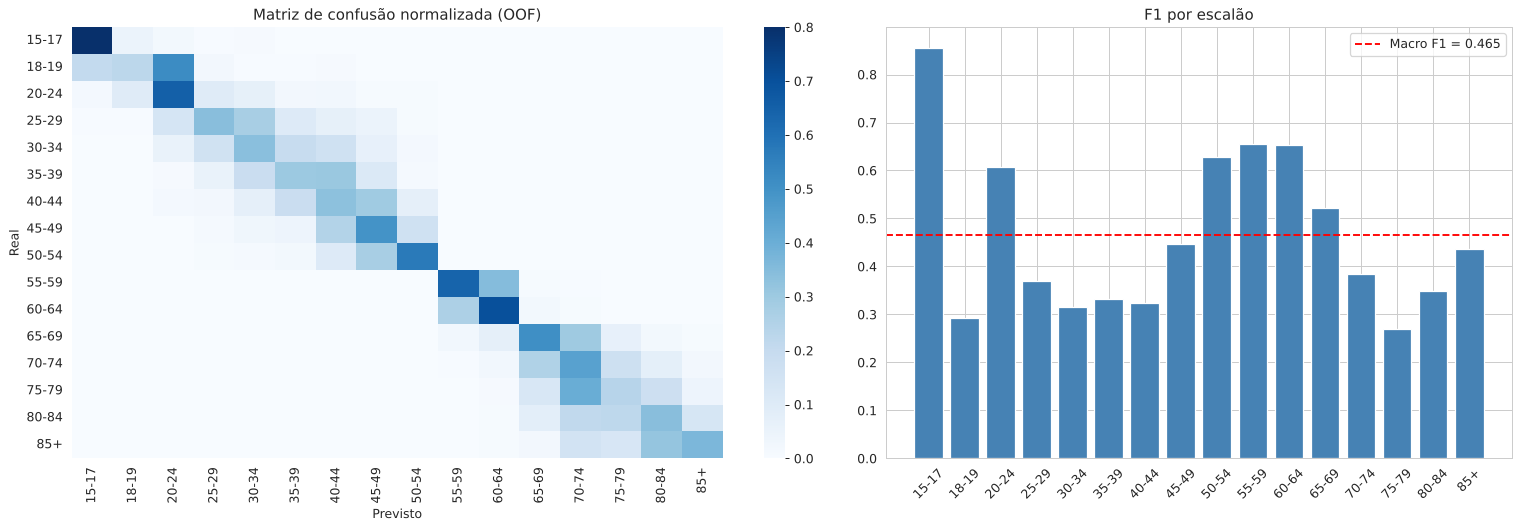

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={'width_ratios': [1.3, 1]})
cm = confusion_matrix(y, pred_oof, normalize='true')
sns.heatmap(cm, cmap='Blues', xticklabels=AGE_LABELS, yticklabels=AGE_LABELS, ax=axs[0], vmax=0.8)
axs[0].set_xlabel('Previsto'); axs[0].set_ylabel('Real'); axs[0].set_title('Matriz de confusão normalizada (OOF)')
f1c = f1_score(y, pred_oof, average=None)
axs[1].bar(AGE_LABELS, f1c, color='steelblue'); axs[1].axhline(f1c.mean(), color='red', ls='--', label=f'Macro F1 = {f1c.mean():.3f}')
axs[1].tick_params(axis='x', rotation=45); axs[1].set_title('F1 por escalão'); axs[1].legend()
plt.tight_layout(); plt.show()

Os erros concentram-se nas classes vizinhas, ou seja, na diagonal da matriz. A fronteira dos 55 anos nunca é ultrapassada, por causa da regra de salto PC1/HA1. Os escalões mais difíceis estão no meio de cada bloco (25–44 e 65–79), onde o perfil muda pouco de 5 em 5 anos.

## 6. Interpretação — importância das variáveis
Usamos a *permutation importance*: mede quanto a Macro F1 desce quando se baralha cada variável. É calculada num fold de validação.

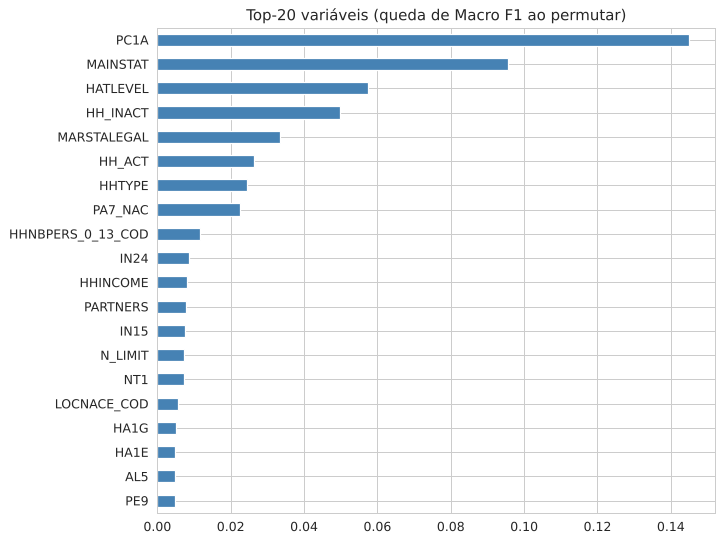

In [19]:
a, b = next(skf.split(X, y))
m = make_hgb().fit(X.iloc[a], y[a])
pi = permutation_importance(m, X.iloc[b], y[b], scoring='f1_macro', n_repeats=3, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
imp.head(20)[::-1].plot(kind='barh', figsize=(8, 7), color='steelblue')
plt.title('Top-20 variáveis (queda de Macro F1 ao permutar)'); plt.show()

## 7. Anomalias epidemiológicas
Para cada indivíduo do treino, calculamos a **idade prevista esperada** a partir das probabilidades OOF: $\hat{a} = \sum_k p_k \cdot k$. Como são OOF, o modelo nunca viu a idade real dessa pessoa.

O desvio bruto $\hat{a} - a$ tem um enviesamento de **regressão para a média**: os mais novos de cada bloco tendem a ser previstos como mais velhos, e os mais velhos como mais novos. Por isso, o desvio é **padronizado dentro de cada escalão real** (z-score). Uma anomalia é um caso com $|z| > 2$:
- $z > 2$: **perfil envelhecido**, o perfil biológico e de estilo de vida é típico de pessoas mais velhas;
- $z < -2$: **perfil atipicamente jovem**.

tipo
normal         10477
jovem            253
envelhecido      232
Name: count, dtype: int64


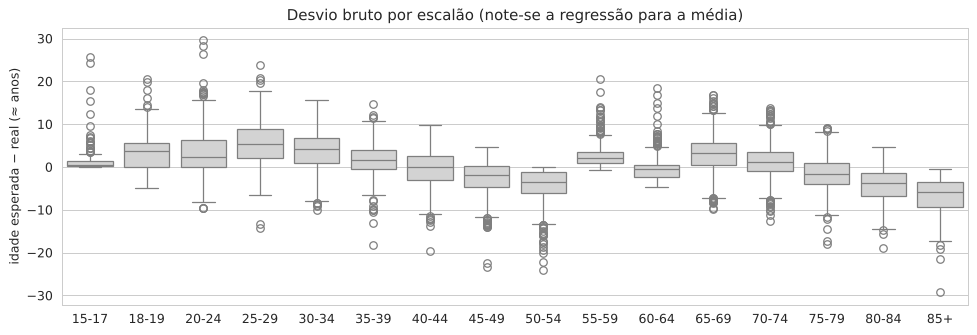

In [20]:
anom = pd.DataFrame({'PID': train['PID'], 'real': y, 'previsto': pred_oof, 'idade_esperada': oof_hgb @ np.arange(K)})
anom['desvio'] = anom['idade_esperada'] - anom['real']
g = anom.groupby('real')['desvio']
anom['z'] = (anom['desvio'] - g.transform('mean')) / g.transform('std')
anom['tipo'] = np.select([anom.z > 2, anom.z < -2], ['envelhecido', 'jovem'], 'normal')

fig, ax = plt.subplots(figsize=(13, 4))
sns.boxplot(x=[AGE_LABELS[k] for k in anom.real], y=anom.desvio * 5, order=AGE_LABELS, color='lightgrey', ax=ax)
ax.set_ylabel('idade esperada − real (≈ anos)'); ax.set_title('Desvio bruto por escalão (note-se a regressão para a média)'); plt.show()
print(anom['tipo'].value_counts())

In [21]:
def indicators(d):
    s = d.astype(str)
    out = pd.DataFrame(index=d.index)
    out['Mulher (%)'] = s['SEX'] == 'Mulher'
    out['Ensino superior (%)'] = s['HATLEVEL'].str.contains('Licenciatura|licenciatura|Doutoramento|Bacharelato|C.T.Superior')
    out['Sem escolaridade (%)'] = s['HATLEVEL'] == 'Nenhum nível completado'
    out['Empregado (%)'] = s['MAINSTAT'].str.startswith('Tem um emprego')
    out['Reformado (%)'] = s['MAINSTAT'].str.startswith('Reformado')
    out['Incapacitado (%)'] = s['MAINSTAT'].str.startswith('Incapacitado')
    out['Viúvo (%)'] = s['MARSTALEGAL'] == 'Viúvo'
    out['1º quintil rendimento (%)'] = s['HHINCOME'] == '1º quintil'
    out['Saúde má/muito má (%)'] = s['HS1'].isin(['Mau', 'Muito mau'])
    out['Severamente limitado (%)'] = s['HS3'] == 'Severamente limitado'
    out['Hipertensão (%)'] = s['CD1E'] == 'Sim'
    out['Diabetes (%)'] = s['CD1J'] == 'Sim'
    out['Depressão (%)'] = s['CD1O'] == 'Sim'
    out['Colesterol (%)'] = s['CD1P'] == 'Sim'
    out['Dificuldade em andar (%)'] = s['PL6'].isin(['Muita dificuldade', 'Não consegue de todo'])
    out['Fuma diariamente (%)'] = s['IN43'] == 'Fuma diariamente'
    out['Álcool diário (%)'] = s['AL1'] == 'Todos os dias ou quase todos os dias'
    out['Fruta diária (%)'] = s['DH1'] == 'Uma vez ou mais por dia'
    out['Obesidade IMC≥30 (%)'] = d['BMI'] >= 30
    out = out.astype(float) * 100
    out['Nº doenças crónicas'] = d['N_CHRONIC']
    out['IMC médio'] = d['BMI']
    return out

ind = indicators(X)
comp_anom = ind.groupby(anom['tipo']).mean().T.round(1)
comp_anom[['jovem', 'normal', 'envelhecido']]

tipo,jovem,normal,envelhecido
Mulher (%),43.9,57.5,50.9
Ensino superior (%),19.0,16.4,6.0
Sem escolaridade (%),4.7,10.0,28.4
Empregado (%),56.1,44.5,19.8
Reformado (%),19.4,35.1,56.5
Incapacitado (%),2.0,2.4,8.6
Viúvo (%),5.5,15.3,25.0
1º quintil rendimento (%),24.5,19.3,20.7
Saúde má/muito má (%),6.3,15.1,40.5
Severamente limitado (%),4.0,7.0,33.2


A tabela compara os três grupos, mas os grupos não têm a mesma distribuição de idades. Uma comparação mais justa é a de cada anómalo **contra os pares do mesmo escalão real**, que é a diferença média abaixo:

In [22]:
dif = ind.sub(ind.groupby(anom['real']).transform('mean'))
by_type = dif.groupby(anom['tipo']).mean().T.round(1)[['jovem', 'envelhecido']]
by_type.columns = ['Jovem vs pares', 'Envelhecido vs pares']
by_type.sort_values('Envelhecido vs pares', ascending=False)

,Jovem vs pares,Envelhecido vs pares
Severamente limitado (%),-4.1,26.2
Saúde má/muito má (%),-10.0,25.0
Dificuldade em andar (%),-5.7,24.9
Sem escolaridade (%),-6.8,18.9
Reformado (%),-19.9,16.0
Viúvo (%),-11.3,9.7
Hipertensão (%),-12.4,8.6
Depressão (%),-7.6,7.9
Diabetes (%),-4.0,7.6
Incapacitado (%),-0.3,6.2


In [23]:
# Casos mais extremos (para discussão no relatório)
top = anom[anom.tipo != 'normal'].assign(real_lbl=lambda d: d.real.map(dict(enumerate(AGE_LABELS))),
                                         prev_lbl=lambda d: d.previsto.map(dict(enumerate(AGE_LABELS))))
cols_show = ['PID', 'real_lbl', 'prev_lbl', 'z', 'tipo']
extra = X[['HS1', 'MAINSTAT', 'N_CHRONIC', 'N_LIMIT', 'BMI']].astype(str)
show = top.join(extra).sort_values('z')
pd.concat([show.head(5), show.tail(5)])[cols_show + list(extra.columns)]

,PID,real_lbl,prev_lbl,z,tipo,HS1,MAINSTAT,N_CHRONIC,N_LIMIT,BMI
2567,10381.0,45-49,18-19,-5.773360,jovem,Mau,Desempregado,3,0,23.437499999999996
10571,13301.0,85+,55-59,-5.537678,jovem,Bom,Tem um emprego ou trabalho (inc. trabalhador familiar não remunerado e em estágio profissional),0,0,24.61810377477591
7508,2495.0,50-54,20-24,-5.503156,jovem,Razoável,Desempregado,1,0,26.722872520606725
862,5034.0,45-49,15-17,-5.501463,jovem,Razoável,"Aluno, estudante, ou em estágio curricular",0,0,29.000594883997625
8069,3983.0,35-39,15-17,-5.263001,jovem,Razoável,"Aluno, estudante, ou em estágio curricular",1,0,24.97398543184183
1383,3024.0,15-17,30-34,7.007351,envelhecido,Bom,Outra situação de inatividade,2,0,23.140495867768596
8065,8549.0,60-64,85+,7.109249,envelhecido,Mau,"Reformado, com reforma antecipada ou cessou a atividade",6,6,25.30864197530864
10888,13853.0,15-17,25-29,7.430226,envelhecido,Razoável,"Aluno, estudante, ou em estágio curricular",2,0,24.163265306122447
920,3556.0,60-64,85+,7.718805,envelhecido,Muito mau,"Reformado, com reforma antecipada ou cessou a atividade",3,9,21.926125822229718
3736,6870.0,55-59,85+,8.263852,envelhecido,Mau,Incapacitado permanente para o trabalho,3,6,22.892819979188342


## 8. Caracterização dos escalões etários

In [24]:
prof = ind.groupby(y).mean().round(1)
prof.index = AGE_LABELS
prof.T

,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
Mulher (%),53.6,47.1,51.1,54.1,59.5,56.6,55.3,54.8,57.3,52.8,58.6,54.3,58.8,63.4,62.8,63.5
Ensino superior (%),0.0,2.9,22.3,33.7,30.5,29.8,31.8,24.1,18.8,13.9,12.0,12.0,7.5,6.8,4.0,5.0
Sem escolaridade (%),1.0,0.0,0.0,0.5,1.1,0.9,0.5,2.0,3.4,4.3,6.0,6.9,14.6,26.7,43.2,47.4
Empregado (%),0.5,10.5,46.1,75.3,82.0,86.7,85.0,82.6,76.7,67.9,40.6,13.8,2.3,1.2,0.2,0.4
Reformado (%),0.0,0.0,0.0,0.3,0.0,0.0,0.5,0.8,2.1,6.8,31.4,72.2,90.4,88.7,90.6,89.9
Incapacitado (%),0.0,0.0,0.0,1.1,2.0,0.9,1.6,2.4,3.1,4.1,6.1,3.6,1.3,1.5,1.5,2.6
Viúvo (%),0.0,0.6,0.3,0.5,0.0,0.3,0.8,1.9,3.8,6.4,11.6,15.8,27.3,40.0,53.1,63.5
1º quintil rendimento (%),63.8,55.2,39.8,26.0,22.7,20.7,20.4,23.2,20.8,20.6,21.8,13.8,7.3,10.2,8.2,11.1
Saúde má/muito má (%),0.5,0.6,1.3,1.6,2.7,1.7,3.3,6.7,10.1,11.3,16.9,17.3,24.1,35.1,39.8,42.9
Severamente limitado (%),0.5,0.6,0.5,1.1,2.2,0.5,1.7,2.6,3.8,6.0,6.3,6.7,10.7,13.7,23.2,31.7


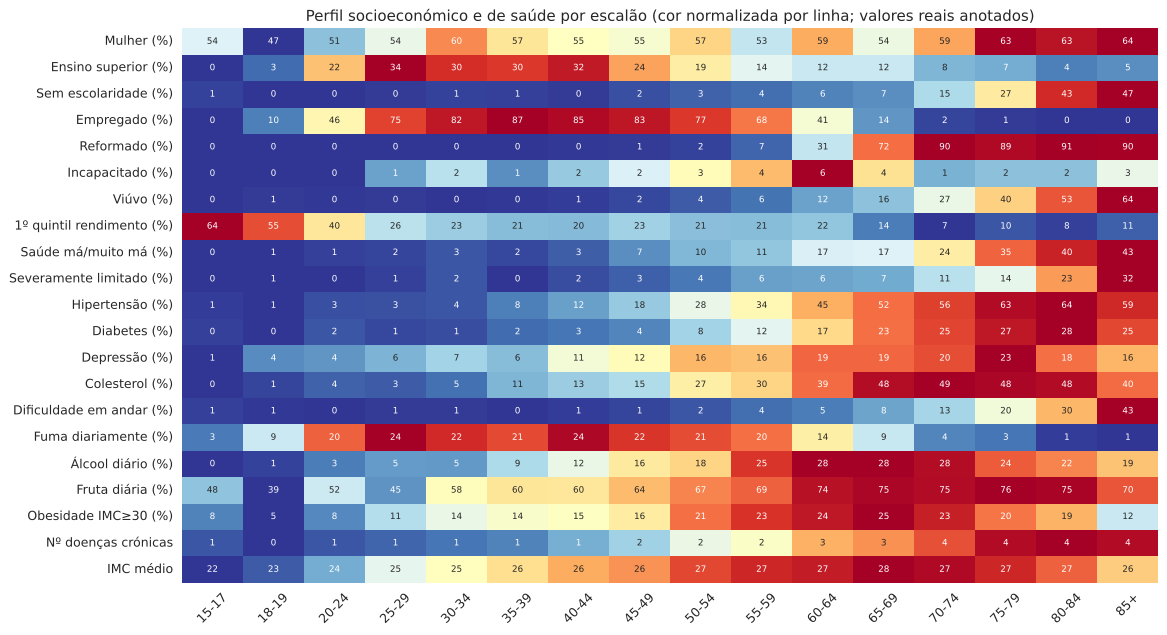

In [25]:
norm = (prof - prof.min()) / (prof.max() - prof.min())
plt.figure(figsize=(14, 8))
sns.heatmap(norm.T, cmap='RdYlBu_r', annot=prof.T.round(0), fmt='g', annot_kws={'size': 7}, cbar=False)
plt.title('Perfil socioeconómico e de saúde por escalão (cor normalizada por linha; valores reais anotados)')
plt.xticks(rotation=45); plt.show()

## 9. Submissão
As probabilidades do teste são a média dos 5 modelos da validação cruzada. Aplicam-se os pesos por classe da secção 5 e escreve-se o CSV no formato do exemplo.

In [26]:
pred_test = (te_hgb * cw).argmax(1)
sub = pd.read_csv('example_submission_10.csv')
sub['AGE_RANGE'] = pred_test
assert sub.shape == (3655, 2) and list(sub.columns) == ['RowId', 'AGE_RANGE']
sub.to_csv('submission_hgb.csv', index=False)
anom.to_csv('anomalias_oof.csv', index=False)
sub['AGE_RANGE'].value_counts().sort_index().rename(index=dict(enumerate(AGE_LABELS))).to_frame('n').T

AGE_RANGE,15-17,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75-79,80-84,85+
n,65,31,159,121,177,154,301,385,233,324,406,327,487,191,193,101


### Próximos passos
- Afinar os hiperparâmetros do boosting (`GridSearchCV` ou `RandomizedSearchCV`) e experimentar LightGBM e CatBoost.
- Fazer um ensemble de modelos (média de probabilidades).
- Explorar feature engineering adicional: indicadores de "módulo não perguntado" e scores agregados por domínio (dieta, atividade física).
- Usar SHAP para explicar as anomalias individualmente.